# Análise exploratória — Preços de revenda de combustíveis no Brasil (2001–2023)

**Projeto Final — Linguagem de Programação VI (Análise e Visualização de Dados com Python)**
Bacharelado em Sistemas de Informação · 6º período · [Semestre] · [Nome da Instituição]
**Autores:** Luan Fernando, Miguel Marreiros

Este notebook é o caderno de exploração, prototipação e validação do projeto. Ele:

1. inspeciona os arquivos **brutos** e documenta os problemas de qualidade encontrados;
2. valida as decisões do pipeline `src/etl.py`;
3. explora os dados tratados para responder às três perguntas de pesquisa:
   - **RQ1** — Como evoluíram os preços médios de revenda entre jul/2001 e jan/2023 e em que momentos se concentram os choques de preço?
   - **RQ2** — Qual é a magnitude da desigualdade de preços entre estados, e ela é persistente?
   - **RQ3** — Onde e quando o etanol hidratado foi economicamente vantajoso frente à gasolina (razão de preços ≤ 0,70)?

> Fonte: ANP — Levantamento de Preços de Combustíveis, agregado mensalmente pelo projeto Economia Popular e distribuído em
> <https://www.kaggle.com/datasets/fidelissauro/combustiveis-brasil>. Preços **nominais** (sem correção pela inflação).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import analise, etl

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
COR = {"gasolina_comum": "#2a78d6", "etanol_hidratado": "#1baf7a", "oleo_diesel": "#eb6834",
       "gas_cozinha_glp": "#6250d6", "gas_natural_veicular_gnv": "#eda100"}
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


## 1. Inspeção dos dados brutos

Os três arquivos de `data/raw/` trazem o mesmo conjunto de colunas de preço em três recortes geográficos (Brasil, 5 regiões, 27 UFs).
As chaves são lidas como texto para não perder o zero à esquerda do mês.

In [2]:
brutos, meta = etl.extrair()
pd.DataFrame(meta).T

,arquivo,sha256,linhas,colunas
BRASIL,combustiveis-brasil.csv,a097057959e3f2ddd955f8afb22badfdcd8cbace93c059...,258,24
REGIAO,combustiveis-regioes.csv,72be1e7651e65e64eb2244ff870a2640b270fb25add314...,1290,25
ESTADO,combustiveis-estados.csv,44bb23eada3619fe859ede06f2ceb0ba5eb565971764f6...,6966,26


In [3]:
estados = brutos["ESTADO"]
nulos = pd.DataFrame({nivel: df.isna().sum() for nivel, df in brutos.items()}).fillna(0).astype(int)
nulos[nulos.sum(axis=1) > 0]

,BRASIL,REGIAO,ESTADO
ano,0,0,16
estado,0,0,16
etanol_hidratado_preco_revenda_avg,0,0,16
etanol_hidratado_preco_revenda_max,0,0,16
etanol_hidratado_preco_revenda_min,0,0,16
gas_natural_veicular_gnv_preco_revenda_avg,0,75,2573
gas_natural_veicular_gnv_preco_revenda_max,0,75,2573
gas_natural_veicular_gnv_preco_revenda_min,0,75,2573
gasolina_aditivada_preco_revenda_avg,230,1150,6211
gasolina_aditivada_preco_revenda_max,230,1150,6211


**Leitura dos nulos.** Há dois tipos de ausência:

* **Estrutural** — `gasolina_aditivada` só passa a ser pesquisada em out/2020 e `oleo_diesel_s10` em dez/2012; o GNV não é vendido em várias UFs. Não há o que imputar: o produto não existia na pesquisa.
* **Anômala** — no arquivo de estados, **16 linhas têm as cinco colunas de chave vazias** (`referencia`, `ano`, `mes`, `regiao`, `estado`), embora tragam preços válidos. Vamos investigá-las.

In [4]:
orfas = estados[estados["estado"].isna()]
print(f"{len(orfas)} linhas sem chave; colunas de preço preenchidas nelas:")
orfas.dropna(axis=1, how="all").head()

16 linhas sem chave; colunas de preço preenchidas nelas:


,gasolina_comum_preco_revenda_avg,gasolina_comum_preco_revenda_min,gasolina_comum_preco_revenda_max,gasolina_aditivada_preco_revenda_avg,gasolina_aditivada_preco_revenda_min,gasolina_aditivada_preco_revenda_max,oleo_diesel_preco_revenda_avg,oleo_diesel_preco_revenda_min,oleo_diesel_preco_revenda_max,oleo_diesel_s10_preco_revenda_avg,oleo_diesel_s10_preco_revenda_min,oleo_diesel_s10_preco_revenda_max,gas_cozinha_glp_preco_revenda_avg,gas_cozinha_glp_preco_revenda_min,gas_cozinha_glp_preco_revenda_max
4724,3.552,3.370,3.690,NaN,NaN,NaN,3.197,2.990,3.325,3.583,3.490,3.660,68.253,63.000,70.000
4751,3.631,3.470,3.850,NaN,NaN,NaN,3.445,3.130,3.690,3.869,3.490,4.020,67.939,63.000,70.000
4859,3.672,3.490,3.980,NaN,NaN,NaN,3.567,3.300,3.690,4.043,3.920,4.090,68.226,63.000,70.000
5237,3.686,3.590,3.890,NaN,NaN,NaN,3.491,3.380,3.760,4.030,3.950,4.090,60.414,58.000,70.000
5264,3.680,3.580,3.890,NaN,NaN,NaN,3.470,3.300,3.760,3.934,3.320,4.090,60.565,58.000,70.000


In [5]:
# Hipótese: cada linha órfã pertence ao mês da linha anterior e à única UF ausente naquele mês.
ref_herdada = estados["referencia"].ffill()
todas = set(estados["estado"].dropna().unique())
diagnostico = pd.DataFrame({
    "linha_csv": orfas.index + 2,
    "mes_herdado": ref_herdada.loc[orfas.index].to_numpy(),
    "ufs_ausentes_no_mes": [sorted(todas - set(estados.loc[estados["referencia"] == m, "estado"].dropna()))
                            for m in ref_herdada.loc[orfas.index]],
})
diagnostico

,linha_csv,mes_herdado,ufs_ausentes_no_mes
0,4726,2016-01,[AMAPA]
1,4753,2016-02,[AMAPA]
2,4861,2016-06,[AMAPA]
3,5239,2017-08,[AMAPA]
4,5266,2017-09,[AMAPA]
5,5293,2017-10,[AMAPA]
6,5563,2018-08,[AMAPA]
7,5671,2018-12,[AMAPA]
8,5698,2019-01,[AMAPA]
9,5752,2019-03,[AMAPA]


Em **todos** os 16 casos falta exatamente uma UF no mês — sempre o **Amapá** — e a linha órfã tem etanol nulo
(tudo indica que, na origem, a ausência do preço do etanol fez a chave se perder em uma junção).
Antes de aceitar a regra, conferimos se os preços da linha órfã são compatíveis com a série do Amapá nos meses vizinhos.

In [6]:
precos = etl.ler_precos() if (etl.DIR_PROCESSED / "precos_combustiveis.csv.gz").exists() else None
if precos is None:
    etl.executar()
    precos = etl.ler_precos()
paridade = etl.ler_paridade()

ap = precos[(precos["uf"] == "AP") & (precos["combustivel"] == "gasolina_comum")].set_index("data")["preco_medio"]
rec = precos[(precos["uf"] == "AP") & (precos["combustivel"] == "gasolina_comum") & precos["chave_recuperada"]]
vizinhos = pd.DataFrame({
    "recuperado": rec.set_index("data")["preco_medio"],
    "mes_anterior_valido": [ap[~ap.index.isin(rec["data"]) & (ap.index < d)].iloc[-1] for d in rec["data"]],
    "mes_seguinte_valido": [ap[~ap.index.isin(rec["data"]) & (ap.index > d)].iloc[0] for d in rec["data"]],
})
vizinhos["dentro_do_intervalo_±5%"] = (
    (vizinhos["recuperado"] >= vizinhos[["mes_anterior_valido", "mes_seguinte_valido"]].min(axis=1) * 0.95)
    & (vizinhos["recuperado"] <= vizinhos[["mes_anterior_valido", "mes_seguinte_valido"]].max(axis=1) * 1.05)
)
print("Linhas recuperadas coerentes com a série do Amapá:",
      int(vizinhos["dentro_do_intervalo_±5%"].sum()), "de", len(vizinhos))
vizinhos.head(8)

Linhas recuperadas coerentes com a série do Amapá: 16 de 16


,recuperado,mes_anterior_valido,mes_seguinte_valido,dentro_do_intervalo_±5%
data,,,,
2016-01-01,3.552,3.549,3.608,True
2016-02-01,3.631,3.549,3.608,True
2016-06-01,3.672,3.632,3.665,True
2017-08-01,3.686,3.504,3.803,True
2017-09-01,3.680,3.504,3.803,True
2017-10-01,3.725,3.504,3.803,True
2018-08-01,3.913,4.033,4.219,True
2018-12-01,3.923,4.085,3.794,True


A regra é aceita: as 16 linhas são reatribuídas ao Amapá e marcadas com `chave_recuperada = True`
(nenhum preço é alterado). O registro completo fica em `data/processed/relatorio_qualidade.json`.

## 2. Visão geral dos dados tratados

O ETL converte os três arquivos para o formato longo (*tidy*): **uma linha por nível geográfico × local × mês × combustível**.

In [7]:
print(f"{len(precos):,} observações | {precos['referencia'].min()} a {precos['referencia'].max()} "
      f"| {precos['referencia'].nunique()} meses")
precos.sample(5, random_state=42)

44,798 observações | 2001-07 a 2023-01 | 258 meses


,nivel_geografico,referencia,data,ano,mes,regiao,uf,estado,combustivel,unidade,preco_medio,preco_minimo,preco_maximo,amplitude_abs,amplitude_rel_pct,var_mensal_pct,var_12m_pct,chave_recuperada,flag_inconsistente
43855,ESTADO,2021-12,2021-12-01,2021,12,Norte,TO,Tocantins,gasolina_comum,R$/L,6.922,6.250,7.499,1.249,18.044,-0.417,42.575,False,False
7725,REGIAO,2006-10,2006-10-01,2006,10,Sul,<NA>,<NA>,oleo_diesel,R$/L,1.885,1.690,2.159,0.469,24.881,-0.106,-0.894,False,False
43668,ESTADO,2006-04,2006-04-01,2006,4,Norte,TO,Tocantins,gasolina_comum,R$/L,2.788,2.630,2.950,0.320,11.478,1.088,13.749,False,False
43067,ESTADO,2020-10,2020-10-01,2020,10,Sudeste,SP,São Paulo,oleo_diesel_s10,R$/L,3.559,3.097,4.399,1.302,36.583,NaN,-4.559,False,False
4832,REGIAO,2023-01,2023-01-01,2023,1,Norte,<NA>,<NA>,etanol_hidratado,R$/L,4.220,3.750,5.800,2.050,48.578,1.687,-26.159,False,False


In [8]:
cobertura = (precos.groupby(["combustivel", "nivel_geografico"])
             .agg(inicio=("referencia", "min"), fim=("referencia", "max"), observacoes=("preco_medio", "size"),
                  locais=("uf", "nunique"))
             .reset_index())
cobertura

,combustivel,nivel_geografico,inicio,fim,observacoes,locais
0,etanol_hidratado,BRASIL,2001-07,2023-01,258,0
1,etanol_hidratado,ESTADO,2001-07,2023-01,6950,27
2,etanol_hidratado,REGIAO,2001-07,2023-01,1290,0
3,gas_cozinha_glp,BRASIL,2001-07,2023-01,258,0
4,gas_cozinha_glp,ESTADO,2001-07,2023-01,6966,27
5,gas_cozinha_glp,REGIAO,2001-07,2023-01,1290,0
6,gas_natural_veicular_gnv,BRASIL,2001-07,2023-01,258,0
7,gas_natural_veicular_gnv,ESTADO,2001-07,2023-01,4393,26
8,gas_natural_veicular_gnv,REGIAO,2001-07,2023-01,1215,0
9,gasolina_aditivada,BRASIL,2020-10,2023-01,28,0


In [9]:
import json
relatorio = json.loads((etl.DIR_PROCESSED / "relatorio_qualidade.json").read_text(encoding="utf-8"))
aud = relatorio["auditoria"]
print("Mês sem coleta nacional:", aud["meses_sem_coleta_nacional"])
print("Inconsistências mín ≤ média ≤ máx:", aud["inconsistencias_min_med_max"])
print("Células vazias omitidas por combustível (soma dos três níveis):")
pd.Series({c: sum(v.values()) for c, v in aud["celulas_vazias_omitidas"].items()})

Mês sem coleta nacional: ['2020-09']
Inconsistências mín ≤ média ≤ máx: 0
Células vazias omitidas por combustível (soma dos três níveis):


gasolina_comum                 0
gasolina_aditivada          7591
etanol_hidratado              16
oleo_diesel                    3
oleo_diesel_s10             4542
gas_cozinha_glp                0
gas_natural_veicular_gnv    2648
dtype: int64

Setembro de 2020 não existe em nenhuma série: a ANP interrompeu a pesquisa durante a troca da empresa contratada e de metodologia.
Por isso as variações do ETL são calculadas **por calendário** (o mês de comparação precisa existir), e não por posição na série.

## 3. RQ1 — Evolução temporal e choques de preço

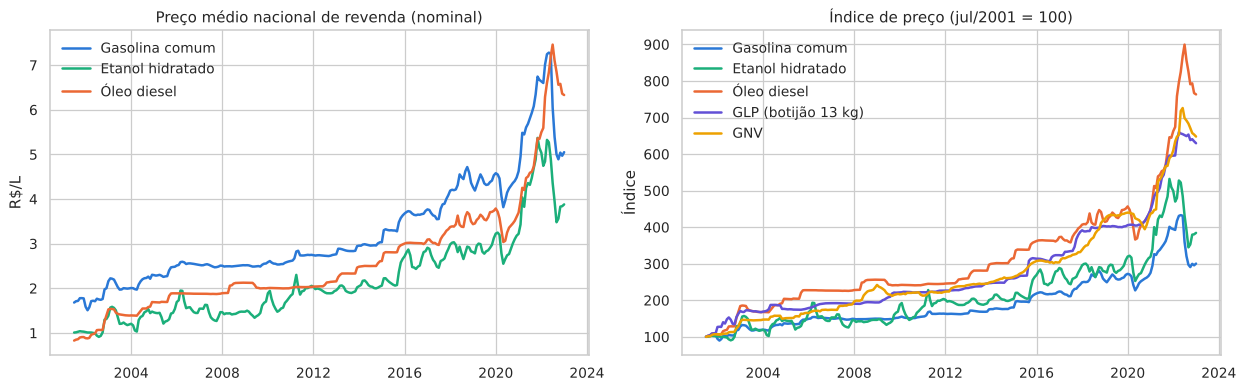

In [10]:
serie = analise.serie_nacional(precos)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5))
for c in ["gasolina_comum", "etanol_hidratado", "oleo_diesel"]:
    eixos[0].plot(serie.index, serie[c], color=COR[c], lw=2, label=analise.rotulo(c))
eixos[0].set(title="Preço médio nacional de revenda (nominal)", ylabel="R$/L")
eixos[0].legend(frameon=False)
indice = analise.indice_base_100(serie[analise.COMBUSTIVEIS_SERIE_LONGA])
for c in indice:
    eixos[1].plot(indice.index, indice[c], color=COR[c], lw=2, label=analise.rotulo(c))
eixos[1].set(title="Índice de preço (jul/2001 = 100)", ylabel="Índice")
eixos[1].legend(frameon=False)
plt.tight_layout(); plt.show()

In [11]:
analise.resumo_periodo(precos)

,inicio,preco_inicial,preco_final,variacao_acumulada_pct,pico,mes_do_pico,meses
combustivel,,,,,,,
gasolina_comum,2001-07,1.681,5.050,200.345,7.280,2022-05,258
gasolina_aditivada,2020-10,4.509,5.220,15.768,7.390,2022-05,28
etanol_hidratado,2001-07,1.009,3.880,284.425,5.370,2021-11,258
oleo_diesel,2001-07,0.829,6.330,663.294,7.460,2022-07,258
oleo_diesel_s10,2012-12,2.226,6.440,189.308,7.570,2022-07,121
gas_cozinha_glp,2001-07,17.195,108.270,529.663,113.513,2022-04,258
gas_natural_veicular_gnv,2001-07,0.730,4.730,547.945,5.300,2022-06,258


O diesel é o combustível que mais encareceu em termos nominais, seguido de GNV e GLP; a gasolina foi a que menos subiu.
Para localizar os **choques**, olhamos a distribuição da variação mensal e aplicamos as cercas de Tukey (1,5 × IQR).

In [12]:
analise.estatisticas_variacao(precos)

,count,mean,median,std,min,max,q1,q3,iqr
combustivel,,,,,,,,,
gasolina_comum,256.000,0.459,0.198,2.807,-16.552,12.300,-0.356,1.108,1.464
gasolina_aditivada,27.000,0.682,1.242,5.247,-15.782,10.770,-0.728,2.902,3.631
etanol_hidratado,256.000,0.631,0.490,5.301,-12.891,28.098,-1.501,2.794,4.295
oleo_diesel,256.000,0.822,0.065,2.754,-7.862,18.337,-0.095,1.211,1.306
oleo_diesel_s10,119.000,0.900,0.266,2.866,-7.449,12.856,-0.095,2.000,2.095
gas_cozinha_glp,256.000,0.738,0.098,2.340,-7.642,16.882,-0.078,0.726,0.804
gas_natural_veicular_gnv,256.000,0.770,0.340,1.990,-5.213,17.033,-0.052,1.112,1.164


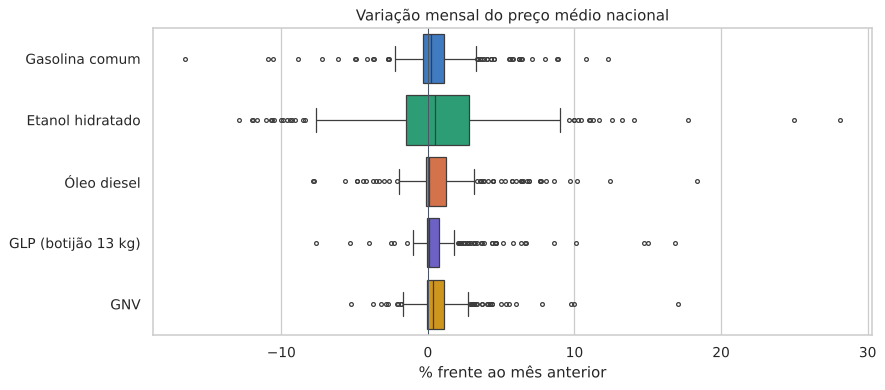

In [13]:
var = analise.serie_nacional(precos, "var_mensal_pct")[analise.COMBUSTIVEIS_SERIE_LONGA]
longo = var.rename(columns=analise.rotulo).melt(var_name="combustivel", value_name="var_mensal_pct").dropna()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=longo, y="combustivel", x="var_mensal_pct", hue="combustivel", legend=False,
            palette=[COR[c] for c in var.columns], fliersize=3, ax=ax)
ax.axvline(0, color="#4b5563", lw=0.8)
ax.set(title="Variação mensal do preço médio nacional", xlabel="% frente ao mês anterior", ylabel="")
plt.tight_layout(); plt.show()

In [14]:
fora = analise.outliers_variacao(precos)
print("Meses outliers por combustível:")
print(fora.groupby("combustivel").size().to_string())
gas = fora[fora["combustivel"] == "gasolina_comum"].assign(mes=lambda d: d["data"].dt.strftime("%Y-%m"))
print("\nGasolina — outliers por período:",
      {"2001–2005": int((gas["data"].dt.year <= 2005).sum()),
       "2006–2019": int(gas["data"].dt.year.between(2006, 2019).sum()),
       "2020–2022": int(gas["data"].dt.year.between(2020, 2022).sum())})
gas.reindex(gas["var_mensal_pct"].abs().sort_values(ascending=False).index)[
    ["mes", "var_mensal_pct", "limite_inferior", "limite_superior", "sentido"]].head(10)

Meses outliers por combustível:
combustivel
etanol_hidratado            31
gas_cozinha_glp             41
gas_natural_veicular_gnv    34
gasolina_aditivada           4
gasolina_comum              39
oleo_diesel                 44
oleo_diesel_s10             20

Gasolina — outliers por período: {'2001–2005': 14, '2006–2019': 12, '2020–2022': 13}


,mes,var_mensal_pct,limite_inferior,limite_superior,sentido
146,2022-07,-16.552,-2.552,3.304,queda
115,2002-11,12.300,-2.552,3.304,alta
147,2022-08,-10.909,-2.552,3.304,queda
141,2021-03,10.765,-2.552,3.304,alta
111,2002-01,-10.548,-2.552,3.304,queda
136,2020-04,-8.875,-2.552,3.304,queda
128,2015-02,8.872,-2.552,3.304,alta
114,2002-04,8.832,-2.552,3.304,alta
116,2003-01,7.968,-2.552,3.304,alta
148,2022-09,-7.236,-2.552,3.304,queda


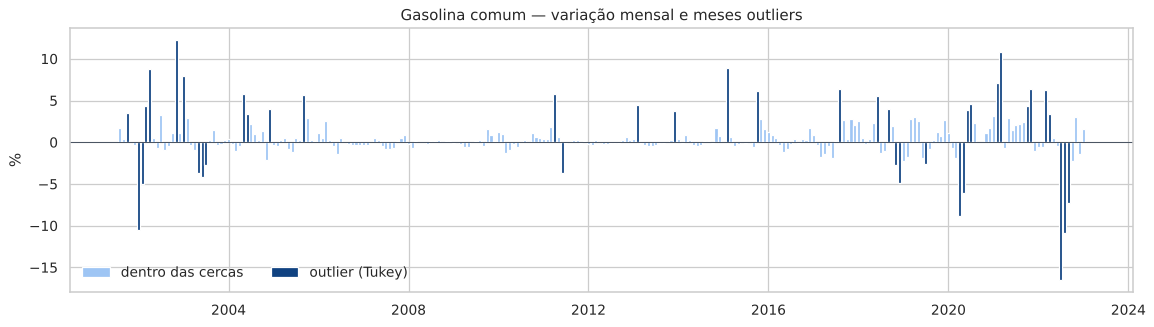

In [15]:
fig, ax = plt.subplots(figsize=(13, 3.8))
v = var["gasolina_comum"].dropna()
eh_outlier = v.index.isin(gas["data"])
ax.bar(v.index[~eh_outlier], v[~eh_outlier], width=25, color="#9ec5f4", label="dentro das cercas")
ax.bar(v.index[eh_outlier], v[eh_outlier], width=25, color="#104281", label="outlier (Tukey)")
ax.axhline(0, color="#4b5563", lw=0.8)
ax.set(title="Gasolina comum — variação mensal e meses outliers", ylabel="%")
ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

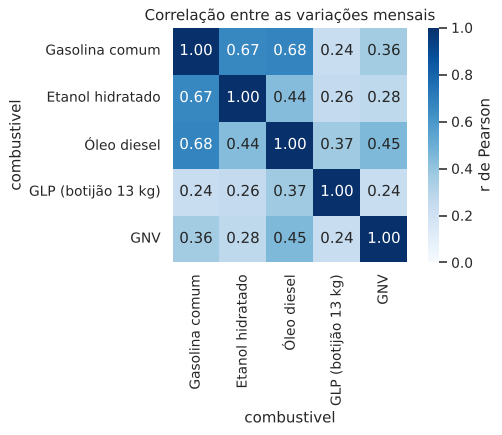

In [16]:
corr = analise.correlacao_variacoes(precos).rename(index=analise.rotulo, columns=analise.rotulo)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, cbar_kws={"label": "r de Pearson"}, ax=ax)
ax.set_title("Correlação entre as variações mensais")
plt.tight_layout(); plt.show()

**Achados (RQ1).** As variações mensais concentram-se perto de zero (medianas entre 0,1 % e 0,5 %) e têm caudas longas: os preços mudam em degraus.
O etanol é o mais volátil. Os outliers da gasolina agrupam-se em dois blocos — 2001–2005 e 2020–2022 — e o maior movimento da gasolina em toda a série é a queda de julho de 2022 (−16,6 %).
Gasolina, diesel e etanol movem-se juntos (r ≈ 0,7); o GLP tem dinâmica própria.

## 4. RQ2 — Desigualdade de preços entre estados

In [17]:
disp = analise.dispersao_interestadual(precos)
combs = ["gasolina_comum", "etanol_hidratado", "oleo_diesel", "gas_cozinha_glp"]
(disp[disp["combustivel"].isin(combs)]
 .groupby("combustivel")[["cv_pct", "razao_max_min"]].agg(["mean", "min", "max"]))

cv_pct              razao_max_min            
                   mean   min    max          mean   min   max
combustivel                                                   
etanol_hidratado 10.611 6.047 18.892         1.587 1.225 2.517
gas_cozinha_glp   8.985 6.473 11.553         1.441 1.263 1.664
gasolina_comum    4.944 3.517  7.222         1.232 1.140 1.460
oleo_diesel       5.990 3.453  8.533         1.274 1.171 1.542

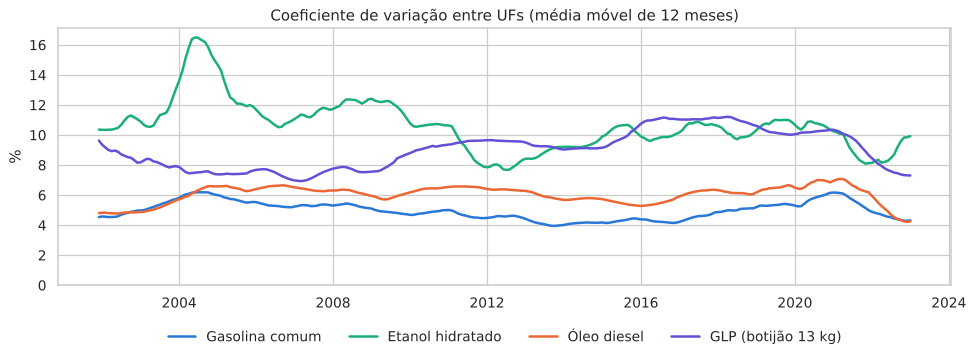

In [18]:
cv = disp.pivot(index="data", columns="combustivel", values="cv_pct")[combs]
fig, ax = plt.subplots(figsize=(11, 4.2))
for c in combs:
    ax.plot(cv.index, cv[c].rolling(12, min_periods=6).mean(), color=COR[c], lw=2, label=analise.rotulo(c))
ax.set(title="Coeficiente de variação entre UFs (média móvel de 12 meses)", ylabel="%", ylim=(0, None))
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

In [19]:
gasolina = disp[disp["combustivel"] == "gasolina_comum"]
print("UF com a gasolina mais cara (nº de meses, de", len(gasolina), "):")
print(gasolina["uf_mais_cara"].value_counts().head(5).to_string())
print("\nUF com a gasolina mais barata:")
print(gasolina["uf_mais_barata"].value_counts().head(5).to_string())

UF com a gasolina mais cara (nº de meses, de 258 ):
uf_mais_cara
AC    193
MT     22
RJ     17
RO     11
PI      6

UF com a gasolina mais barata:
uf_mais_barata
SP    80
AP    55
PI    32
PB    31
AM    11


Para comparar posições ao longo de duas décadas sem interferência da inflação, usamos o **índice relativo**:
preço da UF ÷ mediana das UFs no mesmo mês × 100.

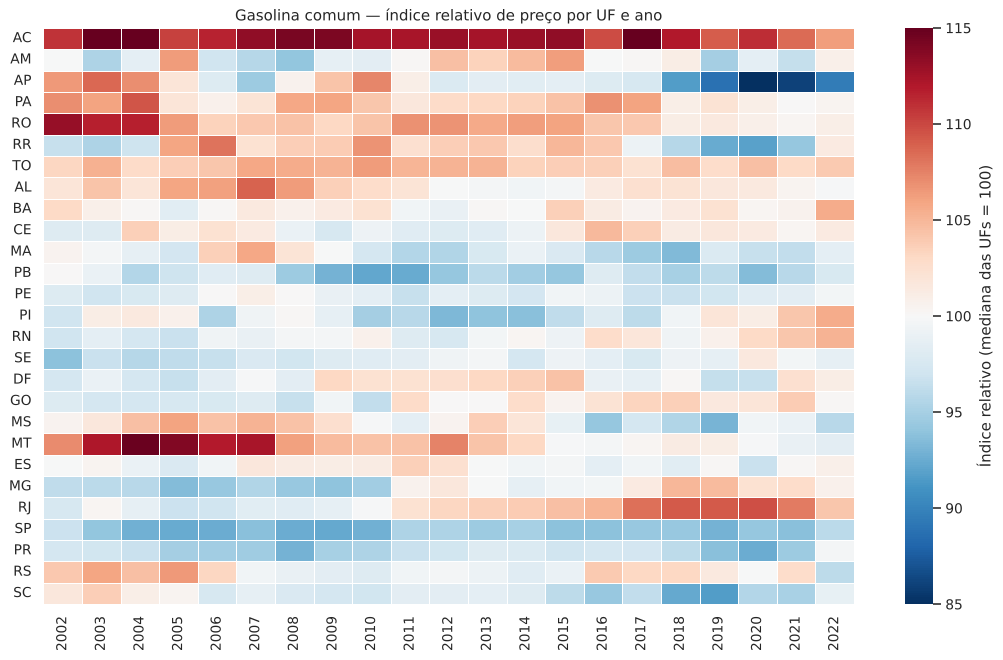

In [20]:
rel = analise.indice_relativo_anual(precos, "gasolina_comum").loc[:, 2002:2022]
ordem = (precos[precos["nivel_geografico"] == "ESTADO"].drop_duplicates("uf")
         .assign(o=lambda d: d["regiao"].map({r: i for i, r in enumerate(analise.ORDEM_REGIOES)}))
         .sort_values(["o", "uf"])["uf"])
fig, ax = plt.subplots(figsize=(12, 7.5))
sns.heatmap(rel.reindex(ordem), cmap="RdBu_r", center=100, vmin=85, vmax=115, linewidths=0.4,
            cbar_kws={"label": "Índice relativo (mediana das UFs = 100)"}, ax=ax)
ax.set(title="Gasolina comum — índice relativo de preço por UF e ano", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

In [21]:
quadros = []
for c in combs:
    r = analise.ranking_estados(precos, c)
    quadros.append(pd.DataFrame({
        "combustivel": analise.rotulo(c),
        "5 mais caras": ", ".join(f"{u} ({v:.0f})" for u, v in zip(r["uf"].head(5), r["indice_medio"].head(5))),
        "5 mais baratas": ", ".join(f"{u} ({v:.0f})" for u, v in zip(r["uf"].tail(5)[::-1], r["indice_medio"].tail(5)[::-1])),
        "Spearman 2001–06 × 2017–23": analise.persistencia_ranking(
            precos, c, ("2001-07-01", "2006-12-01"), ("2017-01-01", "2023-01-01")),
    }, index=[0]))
pd.set_option("display.max_colwidth", 80)
pd.concat(quadros, ignore_index=True)

,combustivel,5 mais caras,5 mais baratas,Spearman 2001–06 × 2017–23
0,Gasolina comum,"AC (112), RO (105), MT (105), TO (104), PA (104)","SP (94), PB (96), PR (96), SC (98), SE (98)",0.126
1,Etanol hidratado,"AC (115), RR (114), PA (114), AP (113), RO (107)","SP (77), PR (84), GO (87), MT (87), MG (91)",0.618
2,Óleo diesel,"AC (121), RR (111), MT (110), RO (108), AP (107)","PR (96), SP (97), PB (97), BA (98), RJ (98)",0.606
3,GLP (botijão 13 kg),"MT (125), AC (114), TO (111), AP (111), RR (110)","PE (92), RJ (93), BA (93), ES (94), AL (95)",0.541


**Achados (RQ2).** A desigualdade é moderada para gasolina e diesel (CV de 4–7 %) e bem maior para etanol e GLP (≈ 9–11 %).
Os extremos são estáveis — Acre no topo, São Paulo e Paraná na base, Norte dominando as primeiras posições —, mas o miolo do ranking da gasolina se reorganiza
(Spearman ≈ 0,13 entre o início e o fim da série), enquanto etanol, diesel e GLP preservam a ordem com mais força (≈ 0,5–0,6).
A dispersão de gasolina, diesel e GLP cai em 2022.

## 5. RQ3 — Paridade etanol/gasolina

In [22]:
br = paridade[paridade["nivel_geografico"] == "BRASIL"]
es = paridade[paridade["nivel_geografico"] == "ESTADO"]
print(f"Razão nacional: média {br['razao_etanol_gasolina'].mean():.3f} | "
      f"mín {br['razao_etanol_gasolina'].min():.3f} | máx {br['razao_etanol_gasolina'].max():.3f}")
print(f"Meses com etanol vantajoso na média nacional: {br['etanol_vantajoso'].mean():.1%}")
print(f"Observações UF-mês com etanol vantajoso:      {es['etanol_vantajoso'].mean():.1%} (n = {len(es):,})")

Razão nacional: média 0.661 | mín 0.512 | máx 0.815
Meses com etanol vantajoso na média nacional: 69.4%
Observações UF-mês com etanol vantajoso:      30.0% (n = 6,950)


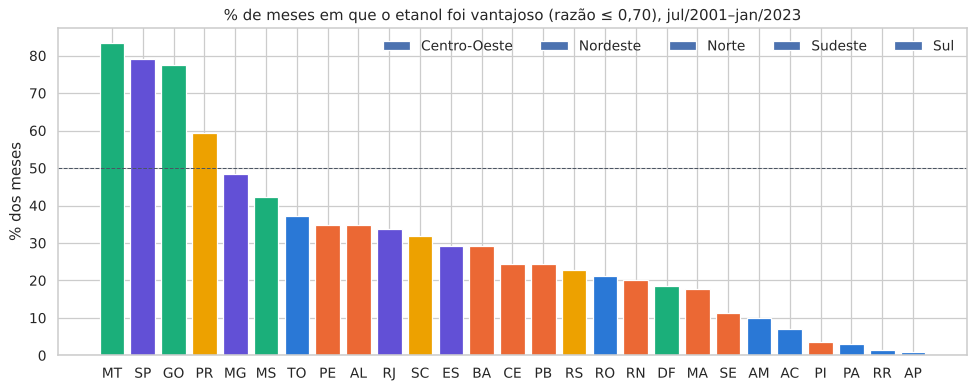

,regiao,uf,estado,razao_media,razao_mediana,pct_meses_vantajoso,meses
0,Centro-Oeste,MT,Mato Grosso,0.630,0.635,83.333,258
1,Sudeste,SP,São Paulo,0.625,0.647,79.070,258
2,Centro-Oeste,GO,Goiás,0.658,0.666,77.519,258
3,Sul,PR,Paraná,0.668,0.679,59.302,258
4,Sudeste,MG,Minas Gerais,0.701,0.704,48.450,258
5,Centro-Oeste,MS,Mato Grosso do Sul,0.720,0.715,42.248,258


In [23]:
por_uf = analise.paridade_resumo_por_uf(paridade)
fig, ax = plt.subplots(figsize=(11, 4.5))
cores = por_uf["regiao"].map({"Norte": "#2a78d6", "Nordeste": "#eb6834", "Centro-Oeste": "#1baf7a",
                              "Sudeste": "#6250d6", "Sul": "#eda100"})
ax.bar(por_uf["uf"], por_uf["pct_meses_vantajoso"], color=cores)
ax.axhline(50, color="#4b5563", lw=0.8, ls="--")
for regiao, cor in cores.groupby(por_uf["regiao"]).first().items():
    ax.bar([], [], color=cor, label=regiao)
ax.legend(frameon=False, ncol=5, loc="upper right")
ax.set(title="% de meses em que o etanol foi vantajoso (razão ≤ 0,70), jul/2001–jan/2023", ylabel="% dos meses")
plt.tight_layout(); plt.show()
por_uf.head(6)

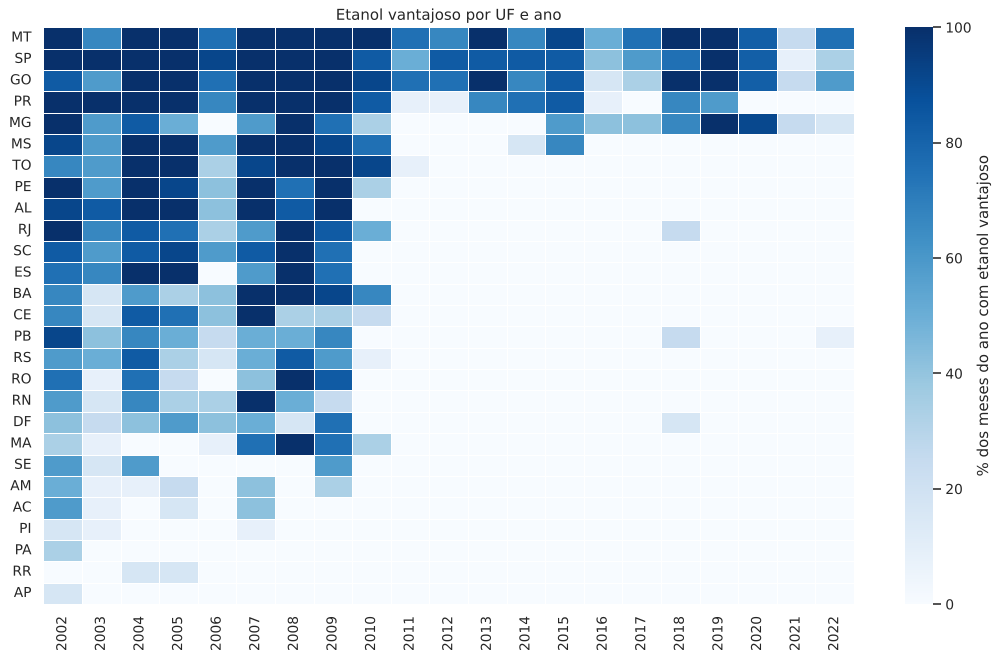

In [24]:
anual = analise.paridade_anual_por_uf(paridade)
mapa = anual.pivot(index="uf", columns="ano", values="pct_meses_vantajoso").reindex(por_uf["uf"]).loc[:, 2002:2022]
fig, ax = plt.subplots(figsize=(12, 7.5))
sns.heatmap(mapa, cmap="Blues", vmin=0, vmax=100, linewidths=0.4,
            cbar_kws={"label": "% dos meses do ano com etanol vantajoso"}, ax=ax)
ax.set(title="Etanol vantajoso por UF e ano", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

Razão nacional média — 2001–2010: 0.609 | 2011–2022: 0.701


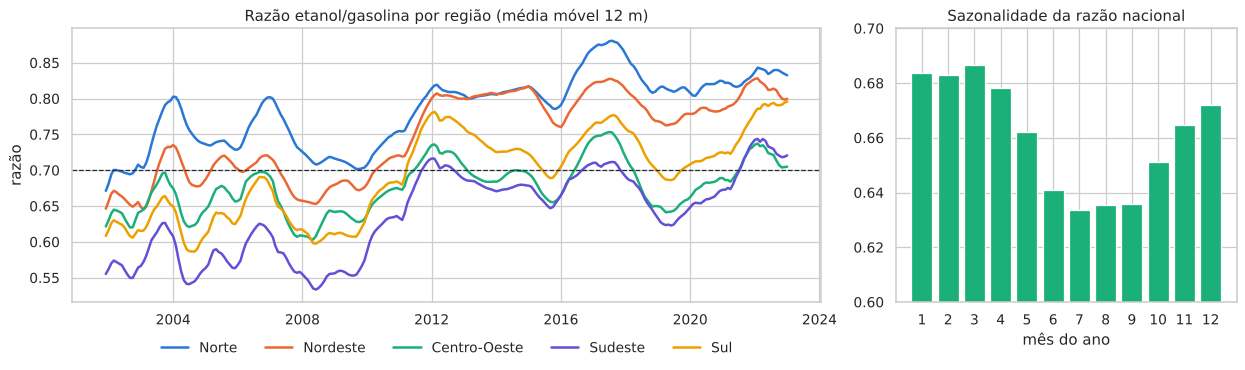

In [25]:
regioes = analise.paridade_por_regiao(paridade)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [2.2, 1]})
paleta = {"Norte": "#2a78d6", "Nordeste": "#eb6834", "Centro-Oeste": "#1baf7a", "Sudeste": "#6250d6", "Sul": "#eda100"}
for r in analise.ORDEM_REGIOES:
    eixos[0].plot(regioes.index, regioes[r].rolling(12, min_periods=6).mean(), color=paleta[r], lw=2, label=r)
eixos[0].axhline(0.70, color="#1f2937", ls="--", lw=1)
eixos[0].set(title="Razão etanol/gasolina por região (média móvel 12 m)", ylabel="razão")
eixos[0].legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
saz = analise.sazonalidade_paridade(paridade)
eixos[1].bar(saz.index, saz.values, color="#1baf7a")
eixos[1].set(title="Sazonalidade da razão nacional", xlabel="mês do ano", ylim=(0.6, 0.7), xticks=range(1, 13))
plt.tight_layout(); plt.show()
print("Razão nacional média — 2001–2010:", round(br.loc[br["ano"] <= 2010, "razao_etanol_gasolina"].mean(), 3),
      "| 2011–2022:", round(br.loc[br["ano"].between(2011, 2022), "razao_etanol_gasolina"].mean(), 3))

**Achados (RQ3).** A média nacional sugere etanol vantajoso em cerca de 69 % dos meses, mas isso só vale para poucos estados:
no nível UF-mês a proporção cai para 30 %. Apenas MT, SP, GO e PR tiveram etanol vantajoso na maioria dos meses; no Norte isso praticamente nunca ocorre.
A competitividade do etanol piorou a partir de 2011 e a razão é sistematicamente menor entre junho e setembro, durante a safra da cana no Centro-Sul.

## 6. Próximos passos

* Os gráficos finais do artigo são gerados por `python -m src.figuras` (figuras estáticas e dados dos gráficos interativos em `docs/assets/`).
* Limitação central: preços nominais. Deflacionar pelo IPCA é o primeiro trabalho futuro.